# Classificação Binária da Qualidade de Vinhos com Machine Learning

## 1. Compreensão do Problema (*Problem Understanding*)

### 1.1 Contexto de Negócio
Na indústria vitivinícola, a avaliação sensorial de vinhos depende de especialistas e envolve subjetividade, tempo e custo operacional. Utilizar dados físico-químicos laboratoriais para apoiar a classificação da qualidade permite padronizar análises e subsidiar decisões produtivas e comerciais.

### 1.2 Definição do Problema de Machine Learning
Trata-se de um problema de **Aprendizado Supervisionado (*Supervised Learning*)** de **Classificação Binária (*Binary Classification*)**, em que buscamos prever a qualidade de amostras de vinho a partir de variáveis físico-químicas (como acidez, teor alcoólico, densidade, pH, sulfatos e dióxido de enxofre).

### 1.3 Variável-Alvo (*Target Variable*) e Premissa de Negócio
A variável original `quality` é convertida na variável binária `target`:
- **Classe 1 (`Alta Qualidade`):** `quality >= 7`
- **Classe 0 (`Baixa/Média Qualidade`):** `quality < 7`

**Premissa Operacional Adotada (Cenário A — Selo / Precificação Premium):**
O modelo apoia a identificação de vinhos candidatos a posicionamento/precificação de maior valor. Nesse contexto, um **Falso Positivo (*False Positive*)** — classificar um vinho comum como *Alta Qualidade* — é considerado o erro mais grave, pois pode gerar frustração do consumidor e desgaste da reputação da marca. Ao mesmo tempo, um **Falso Negativo (*False Negative*)** — deixar de identificar um vinho de *Alta Qualidade* — gera custo de oportunidade, exigindo monitoramento conjunto de **Precision** e **Recall** (além de *F1-Score* e *PR-AUC*).

### 1.4 Limitações Iniciais
- Notas sensoriais originais carregam subjetividade humana.
- Variáveis físico-químicas não capturam sozinhas fatores como *terroir*, safra, guarda em barrica ou dinâmica de mercado.
- A classe positiva (`quality >= 7`) tende a ser minoritária, exigindo cuidados específicos com métricas e validação.

## 2. Análise Exploratória de Dados

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

# Define a raiz do projeto a partir do diretório atual ou da pasta do notebook
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "WineQT.csv"

try:
    df_raw = pd.read_csv(DATA_PATH)
    print(f"Arquivo carregado com sucesso: {DATA_PATH}")
    print(f"Dimensões (linhas, colunas): {df_raw.shape}")
except FileNotFoundError as exc:
    raise FileNotFoundError(
        f"Arquivo não encontrado em '{DATA_PATH}'. Verifique se 'WineQT.csv' está em data/raw/."
    ) from exc

display(df_raw.head(5))
df_raw.info()

Arquivo carregado com sucesso: c:\Users\diego\Projetos\wine-quality-classification\data\raw\WineQT.csv
Dimensões (linhas, colunas): (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


### 2.1 Dicionário de Dados (*Data Dictionary*)

- **`fixed acidity` (*Acidez fixa*):** concentração de ácidos não voláteis que não evaporam facilmente (principalmente ácido tartárico); contribui para a estrutura e sensação de frescor do vinho.
- **`volatile acidity` (*Acidez volátil*):** quantidade de ácidos voláteis (predominantemente ácido acético); em níveis elevados, associa-se a aromas indesejáveis (como vinagre) e perda de qualidade.
- **`citric acid` (*Ácido cítrico*):** presente em pequenas quantidades; pode adicionar frescor e sabor cítrico, além de atuar na estabilidade do vinho.
- **`residual sugar` (*Açúcar residual*):** quantidade de açúcar restante após a fermentação; influencia o dulçor e o corpo da bebida.
- **`chlorides` (*Cloretos*):** teor de sais (como cloreto de sódio) no vinho; níveis altos costumam associar-se a salinidade excessiva e desequilíbrio sensorial.
- **`free sulfur dioxide` (*Dióxido de enxofre livre*):** fração do SO₂ disponível na forma ativa; ajuda a proteger contra oxidação e microrganismos indesejados.
- **`total sulfur dioxide` (*Dióxido de enxofre total*):** soma do SO₂ livre e do SO₂ combinado a outros compostos; indica o nível total de conservante/antioxidante presente.
- **`density` (*Densidade*):** massa por unidade de volume do vinho (próxima à da água, variando conforme teor alcoólico e açúcares/solutos dissolvidos).
- **`pH`:** mede a acidez ativa (escala logarítmica inversa: valores menores indicam maior acidez livre, afetando estabilidade microbiológica e cor).
- **`sulphates` (*Sulfatos*):** aditivos (como sulfato de potássio) que contribuem para os níveis de SO₂ e para a estabilidade/conservação do vinho.
- **`alcohol` (*Teor alcoólico*):** percentual de álcool por volume (% ABV); influencia corpo, percepção sensorial e equilíbrio do vinho.
- **`quality` (*Qualidade original*):** nota sensorial atribuída por especialistas (variável-alvo bruta que será convertida na classificação binária `target`: `1` se `quality >= 7` e `0` se `quality < 7`).
- **`Id` (*Identificador de registro*):** índice/identificador presente no arquivo `WineQT.csv`; não representa característica físico-química do vinho e não deve ser usado como variável preditiva (*feature*) na modelagem.

In [ ]:
# 'Id' é apenas identificador de linha do arquivo, sem significado físico-químico
df_eda = df_raw.drop(columns=["Id"]).copy()

In [4]:
# 1. Cria a variável-alvo binária conforme definido na Etapa 1 (quality >= 7 -> 1; < 7 -> 0)
df_eda = df_raw.copy()
df_eda["target"] = (df_eda["quality"] >= 7).astype(int)

# 2. Exclu a coluna 'Id' pois é apenas identificador de linha do arquivo, sem significado físico-químico
df_eda = df_eda.drop(columns=["Id"])

# 3. Verifica duplicidades
feature_cols = [col for col in df_eda.columns if col not in ["quality", "target"]]
dup_total = df_eda.duplicated().sum()

print(f"Duplicatas exatas (incluindo quality e target): {dup_total}")

# 4. Distribuição da nota original 'quality' e da variável-alvo binária 'target'
print("\nDistribuição da nota original 'quality':")
display(
    pd.DataFrame({
        "contagem": df_eda["quality"].value_counts().sort_index(),
        "percentual_%": (df_eda["quality"].value_counts(normalize=True).sort_index() * 100).round(2),
    })
)

print("\nDistribuição da variável-alvo binária 'target' (0 = <7 | 1 = >=7):")
display(
    pd.DataFrame({
        "contagem": df_eda["target"].value_counts().sort_index(),
        "percentual_%": (df_eda["target"].value_counts(normalize=True).sort_index() * 100).round(2),
    })
)

# 5. Estatísticas descritivas das variáveis numéricas
print("\nEstatísticas descritivas (excluindo 'target'):")
display(df_eda.drop(columns=["target"]).describe().T.round(4))

Duplicatas exatas (incluindo quality e target): 125

Distribuição da nota original 'quality':


,contagem,percentual_%
quality,,
3,6,0.52
4,33,2.89
5,483,42.26
6,462,40.42
7,143,12.51
8,16,1.40



Distribuição da variável-alvo binária 'target' (0 = <7 | 1 = >=7):


,contagem,percentual_%
target,,
0,984,86.09
1,159,13.91



Estatísticas descritivas (excluindo 'target'):


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.3111,1.7476,4.6000,7.1000,7.9000,9.1000,15.9000
volatile acidity,1143.0,0.5313,0.1796,0.1200,0.3925,0.5200,0.6400,1.5800
citric acid,1143.0,0.2684,0.1967,0.0000,0.0900,0.2500,0.4200,1.0000
residual sugar,1143.0,2.5322,1.3559,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1143.0,0.0869,0.0473,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,1143.0,15.6155,10.2505,1.0000,7.0000,13.0000,21.0000,68.0000
total sulfur dioxide,1143.0,45.9147,32.7821,6.0000,21.0000,37.0000,61.0000,289.0000
density,1143.0,0.9967,0.0019,0.9901,0.9956,0.9967,0.9978,1.0037
pH,1143.0,3.3110,0.1567,2.7400,3.2050,3.3100,3.4000,4.0100
sulphates,1143.0,0.6577,0.1704,0.3300,0.5500,0.6200,0.7300,2.0000


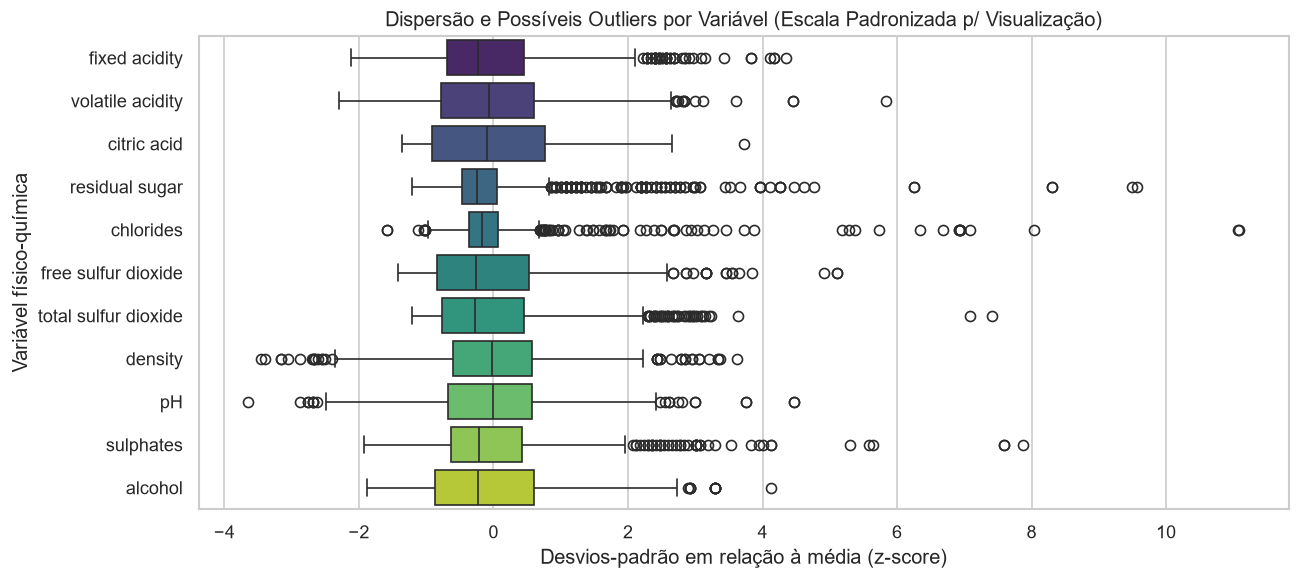

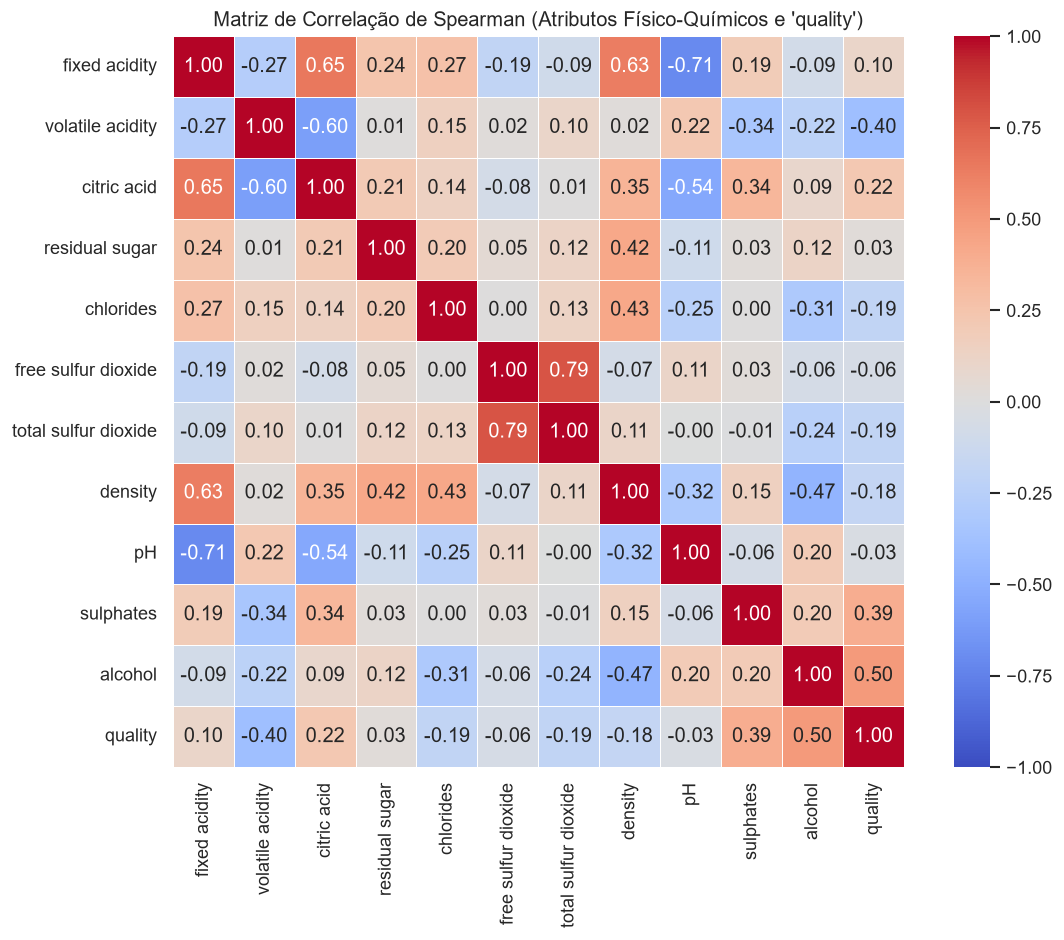

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual consistente
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# 1. Boxplots das variáveis físico-químicas (normalizados por z-score apenas para visualização comparativa)
X_eda = df_eda.drop(columns=["quality", "target"])
X_scaled_vis = (X_eda - X_eda.mean()) / X_eda.std()

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=X_scaled_vis, orient="h", palette="viridis", ax=ax)
ax.set_title("Dispersão e Possíveis Outliers por Variável (Escala Padronizada p/ Visualização)", fontsize=12)
ax.set_xlabel("Desvios-padrão em relação à média (z-score)")
ax.set_ylabel("Variável físico-química")
plt.tight_layout()
plt.show()

# 2. Matriz de correlação de Spearman (mais robusta a assimetrias e relações não lineares que Pearson)
corr_spearman = df_eda.drop(columns=["target"]).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Matriz de Correlação de Spearman (Atributos Físico-Químicos e 'quality')", fontsize=12)
plt.tight_layout()
plt.show()

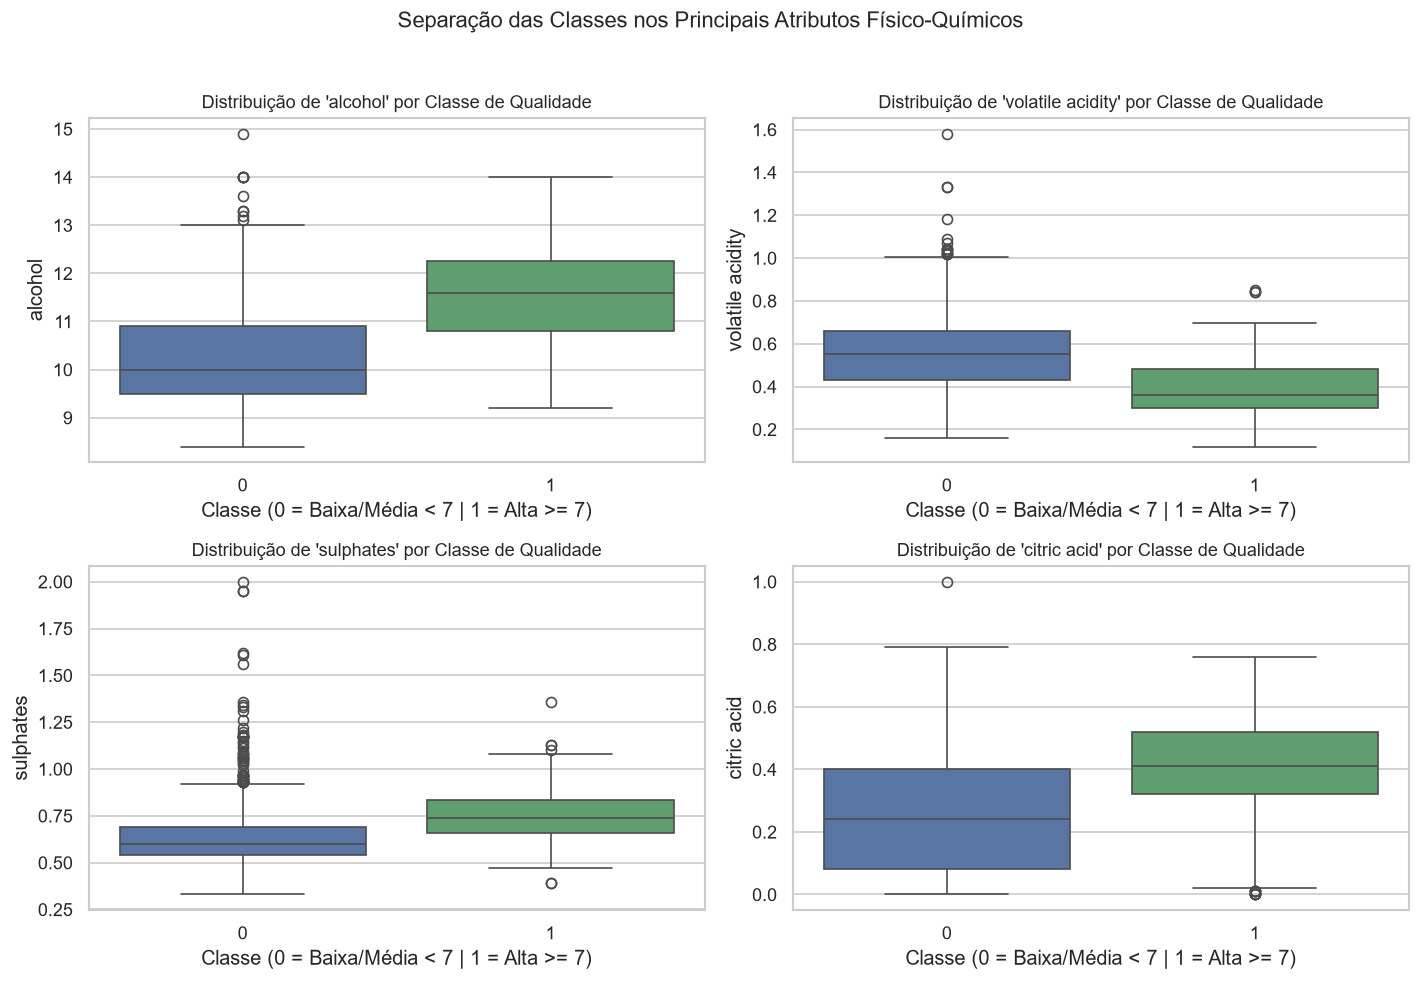

In [ ]:
# Comparação dos 4 atributos físico-químicos mais correlacionados com a variável-alvo 'target' (Spearman)

top_features = ["alcohol", "volatile acidity", "sulphates", "citric acid"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, top_features):
    sns.boxplot(
        data=df_eda,
        x="target",
        y=col,
        hue="target",
        palette={0: "#4C72B0", 1: "#55A868"},
        legend=False,
        ax=ax,
    )
    ax.set_title(f"Distribuição de '{col}' por Classe de Qualidade", fontsize=11)
    ax.set_xlabel("Classe (0 = Baixa/Média < 7 | 1 = Alta >= 7)")
    ax.set_ylabel(col)

plt.suptitle("Separação das Classes nos Principais Atributos Físico-Químicos", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 2.2 Conclusões da Análise Exploratória de Dados (EDA)

A investigação exploratória da base `WineQT.csv` revelou padrões estruturais e físico-químicos essenciais para orientar o pré-processamento e a modelagem:

1. **Integridade e Estrutura dos Dados:**
   - A base original possui **1.143 registros e 13 colunas**, sem valores ausentes (`NaN`).
   - A coluna `Id` foi descartada da análise por ser apenas um identificador sequencial sem significado físico-químico.

2. **Registros Duplicados e Risco de *Data Leakage*:**
   - Foram identificadas **125 amostras duplicadas** considerando os atributos físico-químicos e a nota de qualidade (restam **1.018 registros únicos**).

3. **Desbalanceamento de Classes (*Class Imbalance*):**
   - A variável-alvo binária (`target`: `1` se `quality >= 7`; `0` se `quality < 7`) é fortemente desbalanceada: **86,09%** de vinhos de Baixa/Média Qualidade contra **13,91%** de Alta Qualidade (proporção estrutural mantida mesmo após deduplicação: **86,54% vs. 13,46%**).
   
4. **Assimetrias e Possíveis *Outliers*:**
   - Variáveis como `residual sugar`, `chlorides`, `free sulfur dioxide` e `total sulfur dioxide` apresentam caudas longas à direita e valores máximos bem distantes da mediana e do terceiro quartil (Q3).
   - Essa característica indica a necessidade de avaliar técnicas de escalonamento robustas (como `RobustScaler` em comparação ao `StandardScaler`) no fase de treinamento.

5. **Correlações com a Qualidade (Spearman) e Justificativas Físico-Químicas:**
   - As variáveis com maior associação com `quality` são: **`alcohol` (+0,50)**, **`volatile acidity` (-0,40)**, **`sulphates` (+0,39)** e **`citric acid` (+0,22)**.
   - Entre os atributos preditores, destacam-se correlações fortes com fundamento químico claro — que também sinalizam potencial **multicolinearidade (*multicollinearity*)**:
     - `free sulfur dioxide` vs. `total sulfur dioxide` (**+0,79**): o SO₂ total é composto diretamente pela soma da fração livre com a fração combinada.
     - `fixed acidity` vs. `pH` (**-0,71**): quanto maior a concentração de ácidos fixos na solução, menor o pH (maior acidez).
     - `fixed acidity` vs. `citric acid` (**+0,65**): o ácido cítrico é um ácido não volátil que integra a acidez fixa.
     - `fixed acidity` vs. `density` (**+0,63**): maior concentração de ácidos e solutos dissolvidos eleva a densidade do líquido.
     - `density` vs. `alcohol` (**-0,47**): como o álcool é menos denso que a água, vinhos com maior teor alcoólico tendem a ter menor densidade.

6. **Perfil da Classe Positiva e Sobreposição (*Overlap*):**
   - Em termos de mediana, vinhos de **Alta Qualidade (`target = 1`)** tendem a apresentar **maior teor alcoólico**, **maiores níveis de sulfatos e ácido cítrico** e **menor acidez volátil**.
   - Entretanto, os *boxplots* evidenciam **sobreposição considerável (*overlap*)** entre as classes `0` e `1`. Nenhuma característica físico-química é determinística isoladamente, confirmando que a classificação é um problema **multivariado e probabilístico** que justifica o uso de algoritmos de Machine Learning.
